# Studenters karaktergjennomsnitt og selvrapporterte depresjon

Regresjon beskriver hvordan en tallverdi henger sammen med andre variabler.
Klassifikasjon brukes når utfallet er en kategori. Her undersøkes to spørsmål:

1. Hvordan henger karaktergjennomsnitt (CGPA) sammen med arbeids-/studietimer,
   studiepress og økonomisk stress?
2. Hvor godt kan de tre variablene, sammen med CGPA og alder, klassifisere
   om en student har rapportert depresjon?

CGPA er responsvariabelen i den lineære regresjonen. I klassifikasjonen er
responsen `Depression`, kodet 0 (nei) og 1 (ja). Variablene som brukes til å forklare
eller forutsi responsen, kalles forklaringsvariabler. Klyngeanalyse brukes til slutt
som et utforskende tillegg for å beskrive grupper av observasjoner.

Dataene kommer fra [Student Depression Dataset på Kaggle](https://www.kaggle.com/datasets/hopesb/student-depression-dataset).
Resultatene beskriver sammenhenger og registrert selvrapportering, og dokumenterer
ikke årsaker eller kliniske diagnoser. Tidsenheten for `Work/Study Hours`, rekrutteringen
og målingen av depresjon må avklares fra datakilden før rapporten ferdigstilles.

Notatboken følger datarensing, beskrivelse, modelltilpasning og evaluering i denne
rekkefølgen. Råfilen beholdes uendret; tabeller og figurer lagres separat. Oppsett og
kjøreinstruksjoner finnes i README.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

##Lagring av tabell som csv-fil og viser den i notebook
DATAFIL = Path('Student_Depression_Dataset.csv')
FIGURER = Path('figurer')
RESULTATER = Path('resultater')
FIGURER.mkdir(exist_ok=True)
RESULTATER.mkdir(exist_ok=True)
FROE = 42 #tilfeldig seed for reproduserbarhet
REG_VARIABLER = ['Work/Study Hours', 'Academic Pressure', 'Financial Stress']
KLASS_VARIABLER = ['CGPA', *REG_VARIABLER, 'Age']
ANALYSEKOLONNER = [*KLASS_VARIABLER, 'Depression']
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11})


##Lagring av tabell som csv-fil og viser den i notebook
def lagre_tabell(tabell, navn):
    tabell.to_csv(RESULTATER / f'{navn}.csv', index=False, encoding='utf-8')
    display(tabell)

def lagre_figur(figur, navn):
    figur.tight_layout()
    figur.savefig(FIGURER / navn, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(figur)

# SSE er summen av kvadrerte residualer
# SST er summen av kvadrerte avvik fra gjennomsnittet
# R2 er forklaringsgraden, RMSE er rotgjennomsnittlig kvadratfeil
def regresjonsmaal(observert, predikert):
    observert = np.asarray(observert, dtype=float)
    predikert = np.asarray(predikert, dtype=float)
    n = len(observert)
    sse = np.sum((observert - predikert) ** 2)
    sst = np.sum((observert - np.mean(observert)) ** 2)
    r2 = 1 - sse / sst if n > 1 and sst > 0 else np.nan
    rmse = np.sqrt(sse / n)
    return {'R2': r2, 'RMSE': rmse}


## 1. Datakontroll og rensing

Datarensing skal gi et tydelig analysegrunnlag uten å endre svar som bare virker
uvanlige. Materialet avgrenses til personer registrert som studenter. Bare helt
identiske duplikater fjernes.

Modellene trenger tallverdier i alle analysekolonnene. Svar som mangler, ikke kan
tolkes som tall eller ligger utenfor kontrollgrensene, utelates og telles i renseloggen.
Kontrollgrensene er CGPA 0–10, studiepress 0–5, økonomisk stress 1–5, positiv alder,
ikke-negative timer og depresjonsklasse 0 eller 1. Uendelige tall utelates også.
Disse kontrollene erstatter ikke dokumentasjon av hvordan variablene ble målt.

Null er ikke automatisk en manglende verdi: 0 er for eksempel en gyldig depresjonsklasse.
Null i CGPA og studiepress beholdes fordi betydningen er usikker. 
Analysen uten disse observasjonene gjentas senere for å sjekke mot usikkre nullverdier.
Tabellen nedenfor skiller mellom manglende svar, ugyldige svar og nullverdier som beholdes.


In [2]:
raa = pd.read_csv(DATAFIL)
paakrevd = ['id', 'Profession', *ANALYSEKOLONNER]
mangler_kolonner = sorted(set(paakrevd) - set(raa.columns))
if mangler_kolonner:
    raise ValueError(f'Mangler kolonner: {mangler_kolonner}')

df = raa.copy()
renselogg = []
def registrer_steg(navn, foer, etter):
    renselogg.append({'steg': navn, 'foer': foer, 'etter': etter, 'utelatt': foer - etter})

foer = len(df)
# Rydder bort mellomrom i yrkesnavnet før studentavgrensningen.
yrke = df['Profession'].astype('string').str.strip()
er_student = yrke.eq('Student').fillna(False)
df = df.loc[er_student].copy()
registrer_steg('Avgrensning til studenter', foer, len(df))
foer = len(df)
df = df.drop_duplicates().copy()
registrer_steg('Helt identiske rådatadubletter', foer, len(df))


In [3]:
datakontroll = pd.DataFrame({'manglet_foer': df[ANALYSEKOLONNER].isna().sum()})
for kolonne in ANALYSEKOLONNER:
    df[kolonne] = pd.to_numeric(df[kolonne], errors='coerce')
datakontroll['nye_manglende_etter_tallkonvertering'] = (
    df[ANALYSEKOLONNER].isna().sum() - datakontroll['manglet_foer'])

foer = len(df)
df = df.dropna(subset=ANALYSEKOLONNER).copy()
registrer_steg('Manglende analyseverdier', foer, len(df))


In [4]:
gyldig = pd.DataFrame({
    'CGPA': df['CGPA'].between(0, 10),
    'Work/Study Hours': df['Work/Study Hours'].ge(0),
    'Academic Pressure': df['Academic Pressure'].isin([0, 1, 2, 3, 4, 5]),
    'Financial Stress': df['Financial Stress'].isin([1, 2, 3, 4, 5]),
    'Age': df['Age'].gt(0),
    'Depression': df['Depression'].isin([0, 1]),
}, index=df.index)
gyldig &= np.isfinite(df[gyldig.columns])
datakontroll['ugyldige_svar'] = (~gyldig).sum()
foer = len(df)
df = df.loc[gyldig.all(axis=1)].copy()
registrer_steg('Ugyldige eller ikke-endelige analyseverdier', foer, len(df))
df['Depression'] = df['Depression'].astype(int)
if df['id'].isna().any() or df['id'].duplicated().any():
    raise ValueError('ID mangler eller er duplisert. Avklar personidentitet før oppdeling.')
if df.empty or df['Depression'].nunique() != 2:
    raise ValueError('Analysen trenger observasjoner fra begge depresjonsklassene.')

assert sum(steg['utelatt'] for steg in renselogg) + len(df) == len(raa)
datakontroll['nullverdier_beholdt'] = df[ANALYSEKOLONNER].eq(0).sum()
lagre_tabell(datakontroll.rename_axis('variabel').reset_index(), 'datakontroll')
lagre_tabell(pd.DataFrame(renselogg), 'renselogg')
print(f'Rådata: {len(raa)} rader. Analysegrunnlag: {len(df)} studenter.')


,variabel,manglet_foer,nye_manglende_etter_tallkonvertering,ugyldige_svar,nullverdier_beholdt
0,CGPA,0,0,0,9
1,Work/Study Hours,0,0,0,1699
2,Academic Pressure,0,0,0,9
3,Financial Stress,3,0,0,0
4,Age,0,0,0,0
5,Depression,0,0,0,11560


,steg,foer,etter,utelatt
0,Avgrensning til studenter,27901,27870,31
1,Helt identiske rådatadubletter,27870,27870,0
2,Manglende analyseverdier,27870,27867,3
3,Ugyldige eller ikke-endelige analyseverdier,27867,27867,0


Rådata: 27901 rader. Analysegrunnlag: 27867 studenter.


## 2. Beskrivende statistikk

Gjennomsnittet beskriver nivået i en variabel, mens standardavviket beskriver
spredningen rundt gjennomsnittet. 
Minimum og maksimum viser det observerte verdiområdet.
Klassefordelingen viser hvor mange som er registrert med og uten selvrapportert depresjon.

Studiepress og økonomisk stress måles på skalaer med rangerte nivåer. 
Det betyr at nivåene kan ordnes fra lavt til høyt, men at avstanden mellom to påfølgende nivåer ikke nødvendigvis er like stor. Når disse verdiene brukes som tall i modellene, forutsetter vi like avstander mellom nivåene. 
Korrelasjonskoefiienten beskriver lineær samvariasjon mellom to variabler. Verdier nær 1 eller −1 viser henholdsvis sterk positiv eller negativ lineær samvariasjon, mens en verdi nær 0 ikke utelukker andre typer sammenhenger. Korrelasjonen beregnes ved å sammenligne hvordan verdiene avviker fra gjennomsnittene sine.


,variabel,count,mean,std,min,25%,50%,75%,max
0,CGPA,27867.0,7.656084,1.470836,0.0,6.29,7.77,8.92,10.0
1,Work/Study Hours,27867.0,7.157534,3.707136,0.0,4.00,8.00,10.00,12.0
2,Academic Pressure,27867.0,3.140740,1.381637,0.0,2.00,3.00,4.00,5.0
3,Financial Stress,27867.0,3.139520,1.437289,1.0,2.00,3.00,4.00,5.0
4,Age,27867.0,25.821007,4.906538,18.0,21.00,25.00,30.00,59.0
5,Depression,27867.0,0.585172,0.492701,0.0,0.00,1.00,1.00,1.0


,Depression,antall,andel
0,0,11560,0.414828
1,1,16307,0.585172


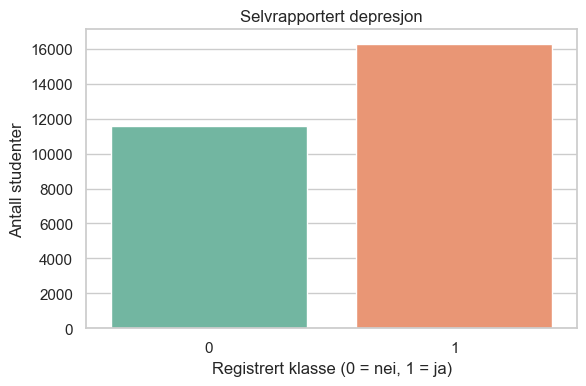

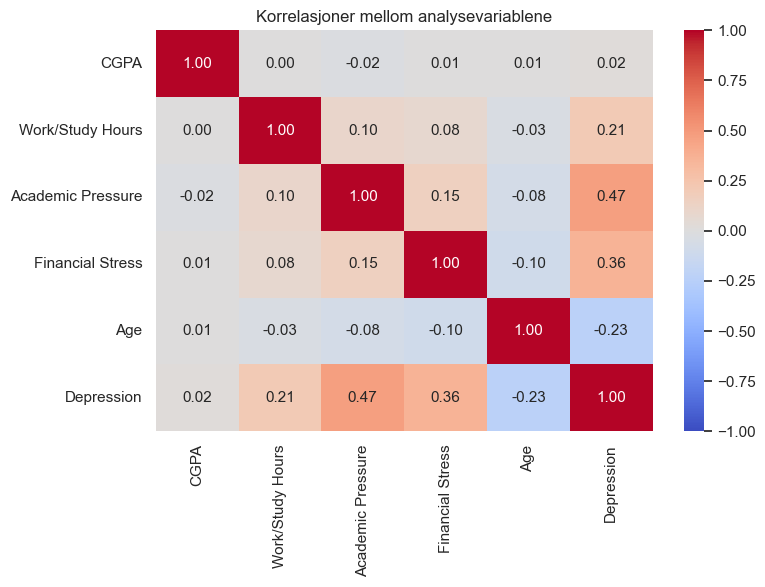

In [5]:
lagre_tabell(df[ANALYSEKOLONNER].describe().T.rename_axis('variabel').reset_index(), 'beskrivende_statistikk')
klasseantall = df['Depression'].value_counts().sort_index()
klasseoversikt = klasseantall.rename_axis('Depression').reset_index(name='antall')
klasseoversikt['andel'] = klasseoversikt['antall'] / len(df)
lagre_tabell(klasseoversikt, 'klassefordeling')
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Depression', hue='Depression', palette='Set2', legend=False, ax=ax)
ax.set(title='Selvrapportert depresjon', xlabel='Registrert klasse (0 = nei, 1 = ja)', ylabel='Antall studenter')
lagre_figur(fig, 'figur1_depresjon_fordeling.png')
fig, ax = plt.subplots(figsize=(8, 6))
verdier = df[ANALYSEKOLONNER].to_numpy(dtype=float)
avvik = verdier - np.mean(verdier, axis=0)
sum_kryssprodukter = avvik.T @ avvik
kvadratsummer = np.sum(avvik ** 2, axis=0)
korrelasjon = sum_kryssprodukter / np.sqrt(np.outer(kvadratsummer, kvadratsummer))
korrelasjon = pd.DataFrame(korrelasjon, index=ANALYSEKOLONNER, columns=ANALYSEKOLONNER)
sns.heatmap(korrelasjon, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korrelasjoner mellom analysevariablene')
lagre_figur(fig, 'figur2_korrelasjonsmatrise.png')

#koden satt opp noe annerledes enn i formelsamlingen med forenklinger, men gir samme resultat.


## 3. Trening, validering og test

En modell kan passe godt til dataene den er tilpasset på uten å forutsi nye
observasjoner godt. Derfor brukes ulike observasjoner til tilpasning og evaluering.
Treningssettet brukes til å beregne modellens koeffisienter, valideringssettet til
å sammenligne modelloppsett og testsettet til å evaluere det endelige oppsettet.

Her fordeles observasjonene i 60 % trening, 15 % validering og 25 % test.
Stratifisering gir omtrent samme andel av hver depresjonsklasse i alle delene.
Et fast tilfeldig seed (FROE=42) gjør oppdelingen reproduserbar. Den tidligere testdelen beholdes.

Logistisk regresjon med tre og fem variabler sammenlignes på valideringssettet.
Femvariabelmodellen er bestemt som hovedmodell på forhånd og beholdes uansett
sammenligningsresultat. 
Deretter beregnes koeffisientene på nytt fra de samlede 75 %
før evalueringen på testsettet. Den lineære modellen tilpasses samme 75 %-del.
Ingen modeller eller terskler justeres etter testresultatene. 

In [6]:
tilpasning75, test = train_test_split(df, test_size=0.25, random_state=FROE, stratify=df['Depression'])
trening60, validering = train_test_split(
    tilpasning75, test_size=0.20, random_state=FROE, stratify=tilpasning75['Depression'])

# «tilpasning75» er den samlede 75 %-delen som brukes ved endelig tilpasning.
klasse_per_del = pd.DataFrame({
    'trening60': trening60['Depression'].value_counts(),
    'validering15': validering['Depression'].value_counts(),
    'endelig_tilpasning75': tilpasning75['Depression'].value_counts(),
    'test25': test['Depression'].value_counts(),
}).reindex([0, 1]).rename_axis('Depression').reset_index()
lagre_tabell(klasse_per_del, 'klassefordeling_trening_test')
print(f'Trening: {len(trening60)}, validering: {len(validering)}, test: {len(test)}.')

assert set(trening60.index).isdisjoint(validering.index)
assert set(trening60.index) | set(validering.index) == set(tilpasning75.index)
assert set(tilpasning75['id']).isdisjoint(test['id'])
assert len(tilpasning75) + len(test) == len(df)


,Depression,trening60,validering15,endelig_tilpasning75,test25
0,0,6936,1734,8670,2890
1,1,9784,2446,12230,4077


Trening: 16720, validering: 4180, test: 6967.


## 4. Multippel lineær regresjon: CGPA

Multippel lineær regresjon beskriver den forventede verdien av en tallrespons
ved hjelp av flere forklaringsvariabler. Modellen for karaktergjennomsnitt er

$$
\mathrm{CGPA}_i
=
\beta_0+\beta_1t_i+\beta_2a_i+\beta_3f_i+\varepsilon_i
$$

der $i$ angir student, $t_i$ er arbeids-/studietimer, $a_i$ er studiepress og
$f_i$ er økonomisk stress. $\beta_0$ er skjæringspunktet og $\varepsilon_i$ er
avviket som modellen ikke forklarer. En koeffisient $\beta_j$ beskriver
sammenhengen mellom den tilhørende forklaringsvariabelen og CGPA.

Minste kvadraters metode (OrdinaryLeastSquares) som gir minst mulig sum av kvadrerte residualer. En residual er forskjellen mellom en observert verdi og modellens predikerte verdi. I koden brukes sm.OLS(...).fit() fra statsmodels til å utføre denne tilpasningen.
Modellen tilpasses på 75 %-delen. Tabellen viser estimater, standardfeil,
95 % konfidensintervaller og p-verdier. Standardfeilen beskriver usikkerheten i et estimat.
Ved gjentatt bruk av en gyldig 95 %-intervallmetode vil omtrent 95 % av intervallene
dekke den sanne koeffisienten. Dette er ikke sannsynligheten for at et bestemt intervall er riktig.

For hver koeffisient testes $H_0:\beta_j=0$ mot $H_1:\beta_j\ne0$.
P-verdien er sannsynligheten, under nullhypotesen og modellforutsetningene, for et
minst like ekstremt testresultat. Den er ikke sannsynligheten for at nullhypotesen er sann.

$R^2$ beskriver hvor stor del av variasjonen responsen får forklart i det aktuelle
datasettet. Justert $R^2$ tar også hensyn til antall forklaringsvariabler. På testsettet
brukes dessuten RMSE, kvadratroten av gjennomsnittlig kvadrert prediksjonsfeil.
RMSE måles i CGPA-poeng, og lavere verdi betyr mindre prediksjonsfeil.
+Både $R^2$ og RMSE beregnes nedenfor direkte fra kvadrerte avvik (SSE og SST). En enkel
referanse predikerer gjennomsnittlig CGPA fra tilpasningsdelen for alle testpersoner.


In [7]:
X_tilpasning = sm.add_constant(tilpasning75[REG_VARIABLER], has_constant='add')
X_test = sm.add_constant(test[REG_VARIABLER], has_constant='add')
ols = sm.OLS(tilpasning75['CGPA'], X_tilpasning).fit()
intervall = ols.conf_int()
koeffisienter = pd.DataFrame({
    'variabel': ols.params.index, 'estimat': ols.params.to_numpy(),
    'standardfeil': ols.bse.to_numpy(), 'p_verdi': ols.pvalues.to_numpy(),
    'KI_95_nedre': intervall[0].to_numpy(), 'KI_95_ovre': intervall[1].to_numpy(),
})
lagre_tabell(koeffisienter, 'regresjon_koeffisienter')


,variabel,estimat,standardfeil,p_verdi,KI_95_nedre,KI_95_ovre
0,const,7.674315,0.035640,0.000000,7.604458,7.744173
1,Work/Study Hours,0.002909,0.002759,0.291749,-0.002499,0.008318
2,Academic Pressure,-0.025123,0.007500,0.000810,-0.039823,-0.010423
3,Financial Stress,0.012676,0.007194,0.078059,-0.001424,0.026776


In [8]:
pred_reg_test = ols.predict(X_test)
reg_testtabell = pd.DataFrame([
    {'modell': 'Lineær regresjon', **regresjonsmaal(test['CGPA'], pred_reg_test)},
    {'modell': 'Treningsgjennomsnitt', **regresjonsmaal(test['CGPA'], np.repeat(tilpasning75['CGPA'].mean(), len(test)))},
])
lagre_tabell(reg_testtabell, 'regresjon_test')
r2_trening = regresjonsmaal(tilpasning75['CGPA'], ols.fittedvalues)['R2']
n = len(tilpasning75)
k = len(REG_VARIABLER)
r2_justert = 1 - (1 - r2_trening) * (n - 1) / (n - k - 1)
print(f'R² på trening: {r2_trening:.6f}. Justert R²: {r2_justert:.6f}.')
print('RMSE måles i CGPA-poeng. Negativ test-R² betyr dårligere enn testsettets gjennomsnitt.')


,modell,R2,RMSE
0,Lineær regresjon,3.697423e-04,1.468062
1,Treningsgjennomsnitt,-2.135335e-07,1.468334


R² på trening: 0.000652. Justert R²: 0.000508.
RMSE måles i CGPA-poeng. Negativ test-R² betyr dårligere enn testsettets gjennomsnitt.


**Resultat:** Modellen forklarer omtrent 0,065 % av CGPA-variasjonen i
tilpasningsdelen ($R^2\approx0{,}000652$). På testsettet er RMSE 1,4681 CGPA-poeng,
mot 1,4683 for referansen. De tre variablene gir dermed nesten ingen forbedring
i prediksjon. Ett trinn høyere studiepress er forbundet med omtrent 0,025 poeng
lavere forventet CGPA når de andre variablene holdes faste. Den klassiske p-verdien
er omtrent 0,0008, men liten p-verdi betyr ikke stor praktisk betydning.
P-verdier som vises som 0 i tabellen, skyldes tallrepresentasjonen og rapporteres ikke som p = 0.

### Regresjonsforutsetninger og residualplott

Et residual er forskjellen mellom en observert verdi og verdien modellen predikerer:

$$
\text{residual} = \text{observert CGPA} - \text{predikert CGPA}
$$

I residualplottet vises residualene på y-aksen og predikert CGPA på x-aksen. Et punkt over null betyr at modellen predikerte for lavt, mens et punkt under null betyr at modellen predikerte for høyt.

Plottet brukes til å undersøke om residualene har et systematisk mønster. Dersom punktene danner en kurve, kan det tyde på at en lineær modell ikke fanger opp hele sammenhengen. Dersom spredningen øker eller minker langs x-aksen, kan det tyde på at feilvariansen ikke er konstant.

Et residualplott gir en grafisk visning av hvor godt modellen predikererde observerte verdiene. og gir en tidlig indikasjon på om modellen er verdt å bruke

I QQ-plottet sammenlignes residualene med verdier fra en normalfordeling. Punktene vil ligge omtrent langs en rett linje dersom residualene er tilnærmet normalfordelte. Tydelige avvik fra linjen kan tyde på at de ikke er det.

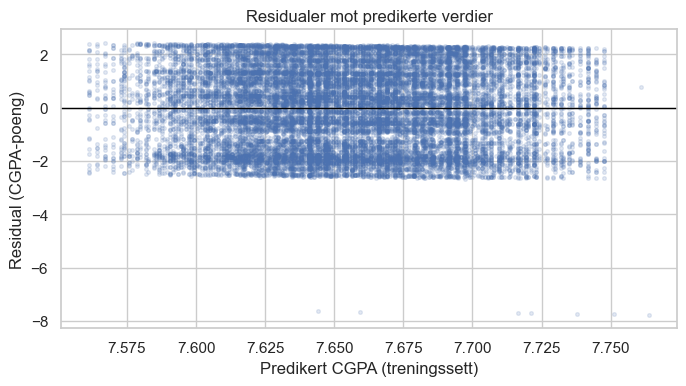

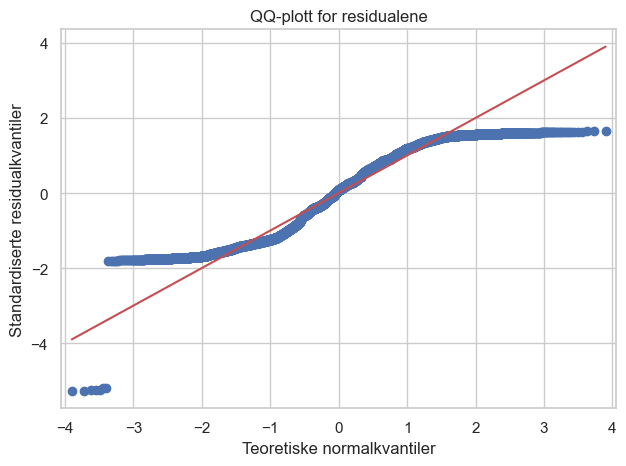

In [9]:
residualer = ols.resid
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ols.fittedvalues, residualer, s=7, alpha=0.15, rasterized=True)
ax.axhline(0, color='black', linewidth=1)
ax.set(xlabel='Predikert CGPA (treningssett)', ylabel='Residual (CGPA-poeng)', title='Residualer mot predikerte verdier')
lagre_figur(fig, 'figur5_residualer.png')

fig = sm.qqplot(residualer, line='s', fit=True)
fig.axes[0].set(title='QQ-plott for residualene', xlabel='Teoretiske normalkvantiler', ylabel='Standardiserte residualkvantiler')
lagre_figur(fig, 'figur6_qq.png')


**Resultat:** QQ-plottet avviker tydelig fra en rett linje, så normalfordeling er
ikke godt støttet. 
Observasjonene med null i CGPA gir store negative residualer.
Dette er ikke ensbetydende med at koeffisientene er ubrukelige, men de klassiske
konfidensintervallene og p-verdiene må vurderes sammen med avvikene fra
modellforutsetningene. 
Figurene gir ikke alene grunnlag for å fastslå konstant
feilvarians, linearitet eller uavhengighet.


## 5. Klassifikasjon/logistisk regresjon

Logistisk regresjon brukes når responsvariabelen har to mulige klasser. I denne analysen er responsvariabelen selvrapportert depresjon:

- **Klasse 0:** Studenten er registrert uten selvrapportert depresjon.
- **Klasse 1:** Studenten er registrert med selvrapportert depresjon.

Modellen bruker forklaringsvariablene til å beregne en sannsynlighet $p_i$ for at student $i$ tilhører klasse 1. Den logistiske funksjonen sørger for at sannsynligheten ligger mellom 0 og 1:

$$
p_i=\frac{\exp(\eta_i)}{1+\exp(\eta_i)},
\qquad
\eta_i=\gamma_0+\gamma_1x_{i1}+\cdots+\gamma_kx_{ik}.
$$

Her er $x_{ij}$ verdien av forklaringsvariabel $j$ for student $i$, og $k$ er antall forklaringsvariabler. Koeffisienten $\gamma_j$ beskriver hvordan en forklaringsvariabel inngår i modellen, mens $\gamma_0$ er skjæringspunktet. Modellen tilpasses uten regularisering, som i forelesningseksempelet.

Det sammenlignes to modeller:

- **Tre variabler:** arbeids-/studietimer, studiepress og økonomisk stress.
- **Fem variabler:** de samme tre variablene, samt CGPA og alder.

For å gjøre sannsynligheten om til en predikert klasse brukes terskelen 0,5. Dersom modellen beregner en sannsynlighet på minst 0,5 for klasse 1, predikeres klasse 1. Ellers predikeres klasse 0.

Modellen antar blant annet at observasjonene er uavhengige, og at forklaringsvariablene har en lineær sammenheng med **log-odds**. Odds er forholdet mellom sannsynligheten for klasse 1 og sannsynligheten for klasse 0: $p/(1-p)$. Modellen krever ikke at forklaringsvariablene er normalfordelte.

### Hvordan vurderes klassifikasjonen?

En **forvekslingsmatrise** sammenligner studentenes registrerte klasse med klassen modellen predikerer. Den viser hvor mange som klassifiseres riktig og feil i hver klasse. Fra disse antallene beregnes:

- **Nøyaktighet:** andelen av alle studentene som klassifiseres riktig.
- **Sensitivitet:** andelen av studentene registrert i klasse 1 som modellen klassifiserer som klasse 1.
- **Spesifisitet:** andelen av studentene registrert i klasse 0 som modellen klassifiserer som klasse 0.

Målene viser ulike sider av modellens resultater. Derfor er det nyttig å se på både sensitivitet og spesifisitet, i tillegg til den samlede nøyaktigheten.


In [10]:
def tilpass_logistikk(data, variabler):
    X = sm.add_constant(data[variabler], has_constant='add')
    modell = sm.Logit(data['Depression'], X).fit(disp=False, maxiter=100)
    if not modell.mle_retvals['converged']:
        raise RuntimeError('Logistisk regresjon konvergerte ikke. Undersøk før videre analyse.')
    return modell

def prediker_klasse(modell, data, variabler):
    X = sm.add_constant(data[variabler], has_constant='add')
    return (modell.predict(X) >= 0.5).astype(int)

def forvekslingsmatrise(observert, predikert):
    observert = np.asarray(observert)
    predikert = np.asarray(predikert)
    tn = np.sum((observert == 0) & (predikert == 0)) # (true negative)
    fp = np.sum((observert == 0) & (predikert == 1)) # (false positive)
    fn = np.sum((observert == 1) & (predikert == 0)) # (false negative)
    tp = np.sum((observert == 1) & (predikert == 1)) # (true positive)
    return np.array([[tn, fp], [fn, tp]])

def klassifikasjonsmaal(observert, predikert):
    tn, fp, fn, tp = forvekslingsmatrise(observert, predikert).ravel()
    return {'noyaktighet': (tp + tn) / (tp + tn + fp + fn),
            'sensitivitet': tp / (tp + fn) if tp + fn else np.nan,
            'spesifisitet': tn / (tn + fp) if tn + fp else np.nan,
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

logit3 = tilpass_logistikk(trening60, REG_VARIABLER)
logit5 = tilpass_logistikk(trening60, KLASS_VARIABLER)
valideringstabell = pd.DataFrame([
    {'modell': 'Tre variabler', **klassifikasjonsmaal(
        validering['Depression'], prediker_klasse(logit3, validering, REG_VARIABLER))},
    {'modell': 'Fem variabler', **klassifikasjonsmaal(
        validering['Depression'], prediker_klasse(logit5, validering, KLASS_VARIABLER))},
])
lagre_tabell(valideringstabell, 'klassifikasjon_validering')


,modell,noyaktighet,sensitivitet,spesifisitet,TN,FP,FN,TP
0,Tre variabler,0.770574,0.836059,0.678201,1176,558,401,2045
1,Fem variabler,0.776794,0.827473,0.705306,1223,511,422,2024


**Resultat:** Fem variabler gir 77,68 % nøyaktighet på valideringssettet, mot 77,06 %
med tre. Spesifisiteten øker fra 67,82 % til 70,53 %, mens sensitiviteten synker
fra 83,61 % til 82,75 %. Flere i klasse 0 klassifiseres altså riktig, mens litt
færre i klasse 1 klassifiseres riktig.

### Valg av modell fra resultater

Den valgte femvariabelmodellen tilpasses på hele 75 %-delen. Testresultatene
sammenlignes med en referanse som alltid velger vanligste klasse i denne delen.
En slik referanse viser hvor høy nøyaktighet som kan oppnås uten å bruke personenes
forklaringsvariabler. Testsettet brukes ikke til å endre variabelsett eller terskel.

Koeffisientene tolkes også som oddsratioer: $\exp(\gamma_j)$ er faktoren oddsen
multipliseres med når variabel $j$ øker med én enhet og de andre holdes faste.
En oddsratio over 1 betyr høyere odds; en verdi under 1 betyr lavere odds.


,modell,noyaktighet,sensitivitet,spesifisitet,TN,FP,FN,TP
0,"Logistisk regresjon, fem variabler",0.783982,0.835909,0.710727,2054,836,669,3408
1,Vanligste treningsklasse,0.585187,1.000000,0.000000,0,2890,0,4077


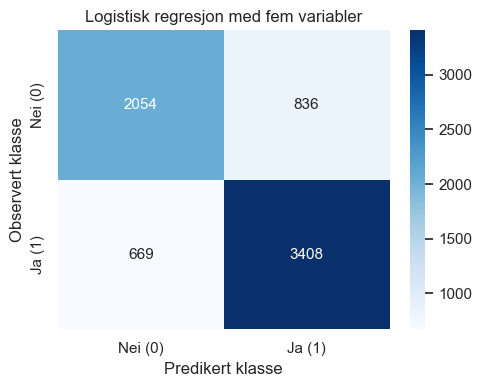

In [11]:
klassifikator = tilpass_logistikk(tilpasning75, KLASS_VARIABLER)
pred_klass_test = prediker_klasse(klassifikator, test, KLASS_VARIABLER)
vanligste_klasse = tilpasning75['Depression'].mode().iloc[0]
pred_referanse = np.repeat(vanligste_klasse, len(test))
klass_testtabell = pd.DataFrame([
    {'modell': 'Logistisk regresjon, fem variabler',
     **klassifikasjonsmaal(test['Depression'], pred_klass_test)},
    {'modell': 'Vanligste treningsklasse',
     **klassifikasjonsmaal(test['Depression'], pred_referanse)},
])
lagre_tabell(klass_testtabell, 'klassifikasjon_test')
cm = forvekslingsmatrise(test['Depression'], pred_klass_test)
assert cm.sum() == len(test)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Nei (0)', 'Ja (1)'],
            yticklabels=['Nei (0)', 'Ja (1)'], ax=ax)
ax.set(xlabel='Predikert klasse', ylabel='Observert klasse', title='Logistisk regresjon med fem variabler')
lagre_figur(fig, 'figur3_forvekslingsmatrise.png')


In [12]:
beta_opprinnelig = klassifikator.params.loc[KLASS_VARIABLER]
odds = pd.DataFrame({'variabel': KLASS_VARIABLER,
                     'koeffisient_original_enhet': beta_opprinnelig.to_numpy(),
                     'oddsratio_per_enhet': np.exp(beta_opprinnelig.to_numpy())})
lagre_tabell(odds, 'klassifikasjon_oddsratio')


,variabel,koeffisient_original_enhet,oddsratio_per_enhet
0,CGPA,0.065741,1.067950
1,Work/Study Hours,0.114784,1.121631
2,Academic Pressure,0.853301,2.347383
3,Financial Stress,0.571574,1.771052
4,Age,-0.104856,0.900454


**Resultat:** Hovedmodellen gir 78,40 % nøyaktighet på testsettet, mot 58,52 % for
referansen. Av 4 077 personer i klasse 1 klassifiseres 3 408 riktig (sensitivitet
83,59 %). Av 2 890 i klasse 0 klassifiseres 2 054 riktig (spesifisitet 71,07 %).
De 669 falske negative er registrert i klasse 1, men predikert til 0. De 836 falske
positive er registrert i klasse 0, men predikert til 1.

Oddsratioen for studiepress er omtrent 2,35 per skalatrinn. Når de andre variablene
holdes faste, er oddsen altså omtrent 2,35 ganger så høy ved ett trinn høyere
studiepress. Dette betyr ikke 2,35 ganger så høy sannsynlighet. For alder er
oddsratioen omtrent 0,90 per år, som tilsvarer omtrent 10 % lavere odds.
Resultatene gjelder registrert selvrapportering i dette materialet.


## 6. Følsomhet for usikre nullverdier

En følsomhetsanalyse undersøker om en bestemt antakelse eller behandling av data
har stor betydning for resultatene. Her gjentas de endelige modellene etter at
observasjoner med null i CGPA eller studiepress er utelatt. De øvrige personene
beholder sin opprinnelige tilhørighet til tilpasningsdelen og testdelen.
Modellform og terskel er uendret. Siden utvalgene blir mindre, brukes sammenligningen
til å vurdere stabilitet, ikke til å velge den varianten som får best testresultat.


In [13]:
tilpasning_uten_null = tilpasning75.loc[tilpasning75['CGPA'].gt(0) & tilpasning75['Academic Pressure'].gt(0)].copy()
test_uten_null = test.loc[test['CGPA'].gt(0) & test['Academic Pressure'].gt(0)].copy()
if min(len(tilpasning_uten_null), len(test_uten_null)) == 0:
    raise ValueError('For få observasjoner til følsomhetsanalysen.')
if tilpasning_uten_null['Depression'].nunique() != 2 or test_uten_null['Depression'].nunique() != 2:
    raise ValueError('Følsomhetsanalysen trenger begge klasser i hver del.')
ols_uten_null = sm.OLS(tilpasning_uten_null['CGPA'], sm.add_constant(tilpasning_uten_null[REG_VARIABLER], has_constant='add')).fit()
pred_reg_uten_null = ols_uten_null.predict(sm.add_constant(test_uten_null[REG_VARIABLER], has_constant='add'))
folsomhet = pd.DataFrame([
    {'variant': 'Hovedanalyse', 'n_trening': len(tilpasning75), 'n_test': len(test),
     'R2_trening': r2_trening, **regresjonsmaal(test['CGPA'], pred_reg_test), **ols.params.to_dict()},
    {'variant': 'Uten null i CGPA eller studiepress', 'n_trening': len(tilpasning_uten_null), 'n_test': len(test_uten_null),
     'R2_trening': regresjonsmaal(tilpasning_uten_null['CGPA'], ols_uten_null.fittedvalues)['R2'], **regresjonsmaal(test_uten_null['CGPA'], pred_reg_uten_null), **ols_uten_null.params.to_dict()},
])
lagre_tabell(folsomhet, 'regresjon_folsomhet_nullverdier')


,variant,n_trening,n_test,R2_trening,R2,RMSE,const,Work/Study Hours,Academic Pressure,Financial Stress
0,Hovedanalyse,20900,6967,0.000652,0.000370,1.468062,7.674315,0.002909,-0.025123,0.012676
1,Uten null i CGPA eller studiepress,20891,6964,0.000804,0.000546,1.462287,7.681376,0.003060,-0.028014,0.013827


In [14]:
klass_uten_null = tilpass_logistikk(tilpasning_uten_null, KLASS_VARIABLER)
pred_klass_uten_null = prediker_klasse(klass_uten_null, test_uten_null, KLASS_VARIABLER)
klass_folsomhet = pd.DataFrame([
    {'variant': 'Hovedanalyse', 'n_trening': len(tilpasning75), 'n_test': len(test),
     **klassifikasjonsmaal(test['Depression'], pred_klass_test)},
    {'variant': 'Uten null i CGPA eller studiepress',
     'n_trening': len(tilpasning_uten_null), 'n_test': len(test_uten_null),
     **klassifikasjonsmaal(test_uten_null['Depression'], pred_klass_uten_null)},
])
lagre_tabell(klass_folsomhet, 'klassifikasjon_folsomhet_nullverdier')


,variant,n_trening,n_test,noyaktighet,sensitivitet,spesifisitet,TN,FP,FN,TP
0,Hovedanalyse,20900,6967,0.783982,0.835909,0.710727,2054,836,669,3408
1,Uten null i CGPA eller studiepress,20891,6964,0.783745,0.835378,0.710873,2053,835,671,3405


**Resultat:** Uten nullverdiene inngår 20 891 observasjoner i tilpasningen og 6 964
i testsettet. Den lineære modellens forklaringskraft er fortsatt nær null, og
klassifikasjonens nøyaktighet er 78,37 %, mot 78,40 % i hovedanalysen. Hovedbildet
endres lite. Dette fastslår verken at nullverdiene er feil eller at utelatelse gir en bedre modell.

## 7. Utforskende klyngeanalyse

K-means grupperer observasjoner etter hvor like de er på valgte variabler,
uten å bruke en kjent responsklasse. Metoden veksler mellom å tilordne hver
observasjon til nærmeste klyngesenter og beregne sentrene som gjennomsnittet
av observasjonene i hver klynge.

Her brukes CGPA, timer, studiepress og økonomisk stress. Variablene standardiseres
til gjennomsnitt 0 og standardavvik 1 før avstander beregnes. Dette hindrer at
en variabel får større vekt bare fordi den har en større tallskala. Tre klynger er
et illustrativt valg; det er ikke undersøkt om dette er et optimalt antall.
Depresjonsklassen inngår ikke i inndelingen, men brukes til å beskrive gruppene
etterpå. Figuren viser to av de fire variablene, og klyngenumrene er vilkårlige etiketter.


,Klynge,CGPA,Work/Study Hours,Academic Pressure,Financial Stress,antall,depresjonsandel
0,0,7.649567,9.274776,2.723235,1.906530,9051,0.441277
1,1,7.672160,2.407652,2.719217,2.886715,8024,0.397308
2,2,7.649596,8.913454,3.804299,4.361564,10792,0.845534


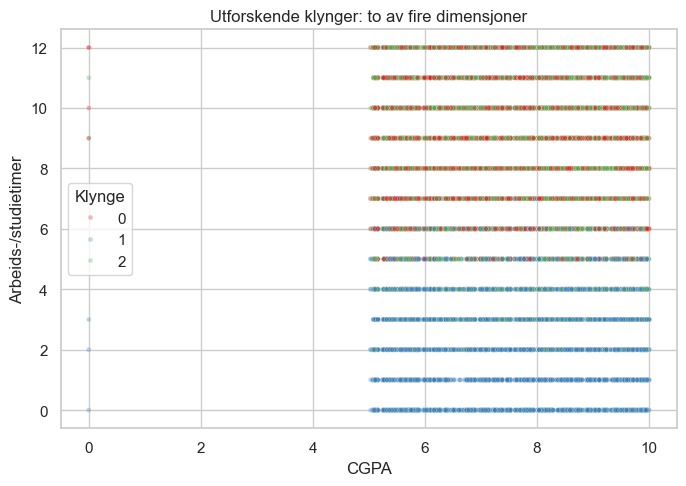

In [15]:
klyngevariabler = ['CGPA', *REG_VARIABLER]
klyngedata = df.copy()
standardiserte_klyngedata = StandardScaler().fit_transform(klyngedata[klyngevariabler])
kmeans = KMeans(n_clusters=3, random_state=FROE, n_init=10)
klyngedata['Klynge'] = kmeans.fit_predict(standardiserte_klyngedata)
klyngetabell = klyngedata.groupby('Klynge')[klyngevariabler].mean()
klyngetabell['antall'] = klyngedata.groupby('Klynge').size()
klyngetabell['depresjonsandel'] = klyngedata.groupby('Klynge')['Depression'].mean()
lagre_tabell(klyngetabell.reset_index(), 'klynger_utforskende')
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=klyngedata, x='CGPA', y='Work/Study Hours', hue='Klynge', palette='Set1', alpha=0.3, s=12, ax=ax)
ax.set(title='Utforskende klynger: to av fire dimensjoner', xlabel='CGPA', ylabel='Arbeids-/studietimer')
lagre_figur(fig, 'figur4_klynger.png')


**Resultat:** Klynge 2 har høyere gjennomsnittlig studiepress og økonomisk stress
enn de andre klyngene, og 84,55 % er registrert i depresjonsklasse 1.
De andre klyngene har andeler på 44,13 % og 39,73 %. Gjennomsnittlig CGPA er
omtrent 7,65–7,67 i alle tre. Klyngene beskriver denne inndelingen av materialet;
de er ikke dokumenterte studenttyper eller kliniske grupper.

## 8. Hva analysene viser

Statistisk signifikans gjelder hvor uforenlige dataene er med en nullhypotese under
modellforutsetningene. Praktisk betydning gjelder størrelsen på sammenhengen, mens
prediksjonsevne gjelder hvor godt modellen treffer observasjoner den ikke er tilpasset
på. Her har studiepress en liten p-verdi i den lineære modellen, samtidig som
koeffisienten er liten og prediksjonen nesten lik gjennomsnittsreferansen.

Den logistiske modellen klassifiserer bedre enn sin enkle referanse, men gjør
begge typer feil. Verken et stort utvalg, gode klassifikasjonsmål eller forskjellige
klynger dokumenterer representativitet eller årsak. Ordinale skårer, usikre
nullverdier, avvik fra regresjonsforutsetningene og mangelfull innsamlingsdokumentasjon
begrenser tolkningen.

Metodegrunnlag: ISTT1003-forelesningene om lineær regresjon (s. 8–12, 23–35),
klassifikasjon (s. 11, 27, 38–46) og klyngeanalyse (s. 14, 19–24).
RMSE, enkle referanser og nullverdikontrollen er supplerende vurderinger.
KI har bidratt til kode og forklaringer; bruken må deklareres, og faglig ansvar
og sluttvurdering ligger hos gruppen.
